# Choosing configurations

This tutorial walks through the ways COBWEB picks which configurations to keep, then runs them against each other on both test systems. It takes about 25 minutes and picks up where `01_building_the_matrices` left off.

Run `make compare` from the repo root before starting. The last two sections read its output.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np

ROOT = "../.."
sys.path.append(f"{ROOT}/src")
from hamiltonians import coupled_modes, hubbard_chain
from utils import epstein_nesbet_order, ground_state, reference_config
from utils import sample_order, weight_order

plt.style.use(f"{ROOT}/figures.mplstyle")
os.makedirs(f"{ROOT}/figures/week2", exist_ok=True)

Same checker as last time, and the same two systems.

In [2]:
def check(guess, answer, tol=0):
    if guess is None:
        print("Put your guess in first, then run this cell again")
        return
    right = guess == answer if isinstance(answer, str) else abs(guess - answer) <= tol
    print(f"Correct, it's {answer}" if right else f"Not quite. You said {guess}, it's {answer}")


H_hub, labels_hub = hubbard_chain(6, 3, 3, U=8.0)
H_vib, labels_vib = coupled_modes(n_modes=3, n_levels=8)
E0_hub, c0_hub = ground_state(H_hub)
E0_vib, c0_vib = ground_state(H_vib)

## Three ways to choose

Last time we kept configurations in order of exact weight. That needs the answer, so it is a reference rather than a method. We keep it around to compare against, but it is not the best possible choice, as we'll see at the end.

The two real methods are perturbation theory, the standard classical approach, and sampling, which is what a quantum computer does.

## Perturbation theory

COBWEB's version is called Epstein-Nesbet selection, and it is the method chemists have used since the 1970s under the name CIPSI ([Huron, Malrieu and Rancurel, 1973](https://doi.org/10.1063/1.1679199)). It grows a set of configurations in rounds:

1. Solve the small problem for the configurations we have so far.
2. Score every configuration we don't have yet. A configuration scores high if it is strongly connected to what we have and close to it in energy. The score is $|\langle D|H|\psi\rangle|^2 / |E - H_{DD}|$, where $\psi$ is the current answer and $D$ is the candidate.
3. Add the 8 best and go again.

It starts from the cheapest configuration, the one with the smallest diagonal entry. On the chain there is a catch: 20 configurations tie for cheapest, since any arrangement with every site singly filled has no repulsion at all. `reference_config` breaks the tie the way perturbation theory would, by how much each one's neighbours lower its energy. We'll see which one it picks, then grow 20 configurations from it.

In [3]:
seed = [reference_config(H_hub)]
up, down = labels_hub[seed[0]]
print(f"Starting configuration: up {up:06b}   down {down:06b}")

order_en = epstein_nesbet_order(H_hub, seed, 20)
print(f"Kept {len(order_en)} configurations")

Starting configuration: up 010101   down 101010
Kept 20 configurations


Notice that it picked the alternating arrangement. Neighbouring electrons with opposite spin can hop onto each other's site and back, which lowers the energy, and alternating spins gives every neighbour pair that chance. Before we added the tie-break, the code grabbed whichever tied configuration came first in the list, `000111` and `111000`, which has only one such pair. That one choice made perturbation theory look much worse than it is.

The exact weight ordering happens to start from this same configuration. Of their first 20 picks, how many do you think they share? Within 3 counts.

In [4]:
my_guess = None

In [5]:
shared = len(set(order_en) & set(weight_order(c0_hub)[:20]))
check(my_guess, shared, tol=3)

Put your guess in first, then run this cell again


They agree on about half. Perturbation theory never sees the exact answer, so it is guessing, and as we'll see at the end its guesses are often better for the energy than the exact weights are.

## Sampling

A quantum computer prepares a state and measures it. Each measurement returns one configuration, picked at random with probability equal to its weight. Measure many times and the common configurations show up often. The machine doesn't solve anything itself: it hands back a list of configurations, and a normal computer diagonalizes the matrix built from them. IBM's software for this, [qiskit-addon-sqd](https://github.com/Qiskit/qiskit-addon-sqd), takes exactly this kind of list as its input.

`sample_order` fakes the measurements by drawing straight from the exact weights. That is generous to the quantum side, since real hardware prepares an approximate state and adds noise on top.

If we measure the chain 20,000 times, how many of its 400 configurations show up at least once? Within 30 counts.

In [6]:
my_guess = None

In [7]:
rng = np.random.default_rng(0)
found_hub, counts_hub = sample_order(c0_hub, 20000, rng)
check(my_guess, len(found_hub), tol=30)
print(f"Most common configurations came back {counts_hub[:5]} times")

Put your guess in first, then run this cell again
Most common configurations came back [3309 3177 1629 1575 1574] times


Now the vibrational system, with the same 20,000 measurements. It has 512 configurations. Before you guess, think back to the weight plot from the last tutorial. Within 15 counts.

In [8]:
my_guess = None

In [9]:
found_vib, counts_vib = sample_order(c0_vib, 20000, rng)
check(my_guess, len(found_vib), tol=15)
print(f"Most common configuration came back {counts_vib[0]} times out of 20000")

Put your guess in first, then run this cell again
Most common configuration came back 17415 times out of 20000


Notice the gap. The vibrational state puts 87% of its weight on one configuration, so most of the 20,000 measurements return that same configuration again and again. Each repeat costs a measurement and tells us nothing new.

## How fast sampling finds new configurations

`make compare` tracked, for 20 separate runs, how many distinct configurations had turned up after each number of measurements. We'll load that and plot it for both systems.

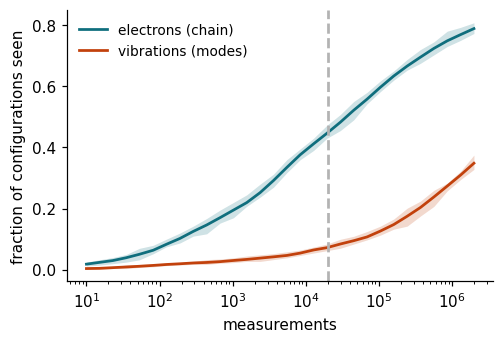

In [10]:
res = {s: np.load(f"{ROOT}/results/compare/{s}.npz") for s in ["hubbard", "modes"]}

fig, ax = plt.subplots(figsize=(5, 3.2))
for s, c, name in [("hubbard", "#0f6e7d", "electrons (chain)"), ("modes", "#c2410c", "vibrations (modes)")]:
    frac = res[s]["discovered"] / res[s]["n_configs"]  # repeats x shots
    ax.semilogx(res[s]["shots"], frac.mean(0), c=c, label=name)
    ax.fill_between(res[s]["shots"], frac.min(0), frac.max(0), color=c, alpha=0.2, lw=0)

ax.axvline(20000, c=(.7, .7, .7), ls="--")  # the budget used above
ax.set_xlabel("measurements")
ax.set_ylabel("fraction of configurations seen")
ax.legend()
fig.savefig(f"{ROOT}/figures/week2/discovery.svg")
plt.show()

Notice that both curves flatten. Early on, nearly every measurement turns up something new. Later, nearly every measurement is a repeat. The shaded band is the spread across the 20 runs.

This flattening is the main published criticism of the quantum approach ([Reinholdt et al., 2025](https://arxiv.org/abs/2501.07231)): the configurations you are still missing are exactly the rare ones, and finding rare things by random sampling is slow. Even after two million measurements, the vibrational system has not shown us half of its configurations.

## Head to head

Now the fair comparison. `make compare` ran all three methods and made each keep exactly k configurations, for many values of k, then recorded the error. For sampling it did this 20 times, since every run comes out a little different.

Before we plot it: on the vibrational system, does sampling ever get the error below 10 cm-1 with 20,000 measurements? Answer "yes" or "no".

In [11]:
my_guess = None

In [12]:
reached = np.nanmin(res["modes"]["err_sample"]) < 10
check(my_guess, "yes" if reached else "no")

Put your guess in first, then run this cell again


We'll plot the error against the number of configurations kept. Sampling is drawn as its median over the 20 runs, with the band covering the middle 80%. Its curve stops where the runs stop finding new configurations, since you cannot keep 200 configurations if only 40 ever came back.

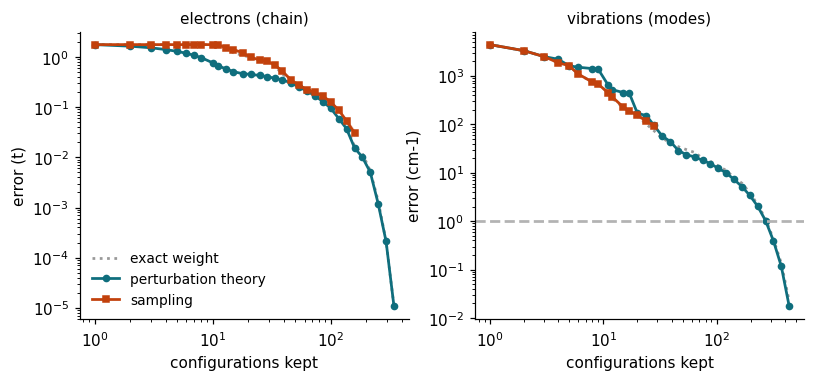

hubbard: sampling found 170 to 193 configurations, median error 0.0304 t at the last size every run reached
    sampling beats perturbation theory at 0 of 27 sizes it reached
    perturbation theory beats exact weight at 30 of 32 sizes
modes: sampling found 32 to 44 configurations, median error 93.3 cm-1 at the last size every run reached
    sampling beats perturbation theory at 11 of 15 sizes it reached
    perturbation theory beats exact weight at 16 of 32 sizes


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.4))
for ax, s, title in [(axes[0], "hubbard", "electrons (chain)"), (axes[1], "modes", "vibrations (modes)")]:
    d = res[s]
    keep = d["sizes"] < d["n_configs"]  # at k = N every method is exact
    sizes = d["sizes"][keep]
    samp = d["err_sample"][:, keep]  # repeats x sizes
    ok = ~np.isnan(samp).any(0)  # sizes every run reached

    ax.loglog(sizes, d["err_weight"][keep], c=(.6, .6, .6), ls=":", label="exact weight")
    ax.loglog(sizes, d["err_en"][keep], "o-", c="#0f6e7d", label="perturbation theory")
    ax.loglog(sizes[ok], np.median(samp[:, ok], 0), "s-", c="#c2410c", label="sampling")
    ax.fill_between(sizes[ok], np.percentile(samp[:, ok], 10, 0),
                    np.percentile(samp[:, ok], 90, 0), color="#c2410c", alpha=0.2, lw=0)
    ax.set_xlabel("configurations kept")
    ax.set_ylabel(f"error ({d['units']})")
    ax.set_title(title)

axes[1].axhline(1.0, c=(.7, .7, .7), ls="--")  # 1 cm-1
axes[0].legend()
fig.savefig(f"{ROOT}/figures/week2/head_to_head.svg")
plt.show()

for s in ["hubbard", "modes"]:
    d = res[s]
    keep = d["sizes"] < d["n_configs"]
    ok = ~np.isnan(d["err_sample"]).any(0)
    med = np.median(d["err_sample"][:, ok], 0)
    print(f"{s}: sampling found {d['n_found'].min()} to {d['n_found'].max()} configurations, "
          f"median error {med[-1]:.3g} {d['units']} at the last size every run reached")
    print(f"    sampling beats perturbation theory at {np.sum(med < d['err_en'][ok])} of {ok.sum()} sizes it reached")
    print(f"    perturbation theory beats exact weight at {np.sum((d['err_en'] < d['err_weight'] - 1e-9) & keep)} of {keep.sum()} sizes")

Three things to notice, with the exact counts in the printout.

First, the orange sampling curve sits on top of the grey exact-weight line until it stops. That is expected. We sample from the exact weights, so the configurations that come back most often are the highest-weight ones, and our sampler can only ever reproduce the weight ordering, cut off wherever it stops finding new configurations. A real quantum circuit would do worse than this, not better.

Second, the two systems disagree. On the chain, perturbation theory beats sampling at every size sampling reaches, by a wide margin when only a few configurations are kept. On the vibrations it goes the other way at small sizes, then sampling stalls somewhere between 30 and 45 configurations with the error still near 90 cm-1, far above the dashed 1 cm-1 line, while perturbation theory keeps going. So which method looks better depends on the system and on how many configurations you can afford. That is the question this project is set up to answer properly.

Third, the grey line is not the lowest. Perturbation theory beats the exact weight ordering at nearly every size on the chain and about half of them on the vibrations. A configuration's weight in the exact answer is not the same as how much it helps the energy of a truncated one.

## What this does and does not show

These are toy models, and the sampler draws from the exact answer instead of a real circuit. So this shows two things: the engine runs end to end on both kinds of system, and on these two models the comparison comes out differently, with perturbation theory ahead on the chain and sampling ahead at small sizes on the vibrations until it stalls. It also shows how much the starting configuration matters, which is worth remembering when we move to real molecules. It does not yet say anything about a real molecule or a real quantum computer. The next weeks swap in real molecules from PySCF and ORCA, and a real circuit in place of the exact weights, without changing any of the code you just ran.

## Things to try

Each of these is one command from the repo root, then rerun the last two sections.

`python src/compare.py -s modes -n 200000 --overwrite` gives sampling ten times the measurements. Does it get under 10 cm-1?

`python src/hamiltonians.py -s modes --coupling 80 --overwrite` followed by `python src/compare.py -s modes --overwrite` makes the modes interact more strongly, which spreads the weight out. Does sampling do better?

`python src/hamiltonians.py -s hubbard -U 2 --overwrite` followed by `python src/compare.py -s hubbard --overwrite` makes the electrons repel less. What happens to the chain's weights?

`make clean` then `make compare` puts everything back to the defaults.